# 04 · Regresión logística (scorecard) vs. benchmark de Lending Club

**Modelo 1 de 5.** Regresión logística sobre variables transformadas a WoE, convertida a un scorecard de puntos.

- Entrenamiento: sep-2012 a 2014 · Validación fuera de tiempo (OOT): 2015.
- **Benchmark (campeón actual):** `int_rate` y `sub_grade`, el score de Lending Club.
- Variables: decisión 004, sin `tot_cur_bal`, `bc_util` ni `antig_credito_meses` (signo contrario a la lógica).

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve
from credit_lab.poblacion import cargar_poblacion
from credit_lab.features import derivar, IV_ALTO, LOGISTICA
from credit_lab.transformadores import preprocesador
from credit_lab.metricas import discriminacion, resumen
from credit_lab.scorecard import modelo_logistica, pd_a_puntos, tabla_puntos

pd.set_option("display.float_format", "{:,.4f}".format)
AZUL, NARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e5e4df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2,
    "ytick.color": TINTA_2, "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "axes.titlecolor": TINTA, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

df = derivar(cargar_poblacion())
tr, oot = df[df["muestra"].eq("train")], df[df["muestra"].eq("oot")]

## 1. Multicolinealidad: VIF antes y después de la decisión 004

VIF > 5 suele indicar que una variable está "explicada" por las demás, lo que vuelve inestables los coeficientes.

In [2]:
def vif(X):
    return pd.Series(np.diag(np.linalg.inv(np.corrcoef(X.values.T))), index=X.columns)

woe_todas = preprocesador("logistica").set_params(woe__n_tramos=10)
X_todas = woe_todas.fit(tr[IV_ALTO], tr["malo"]).transform(tr[IV_ALTO])
pd.DataFrame({"vif_16_variables": vif(X_todas),
              "vif_13_variables": vif(X_todas[LOGISTICA])}).sort_values("vif_16_variables", ascending=False)

,vif_16_variables,vif_13_variables
tot_cur_bal,7.1192,NaN
avg_cur_bal,7.0644,2.2536
total_rev_hi_lim,4.9141,4.8463
total_bc_limit,4.1944,4.1499
mo_sin_old_rev_tl_op,3.7610,1.2449
antig_credito_meses,3.7326,NaN
bc_util,2.8497,NaN
percent_bc_gt_75,2.7409,1.3238
annual_inc,1.9420,1.8747
home_ownership,1.7970,1.7748


In [3]:
lr_todas = LogisticRegression(max_iter=2000).fit(X_todas, tr["malo"])
coef_antes = pd.Series(lr_todas.coef_[0], index=X_todas.columns)
coef_antes[coef_antes > 0].to_frame("coeficiente positivo (signo contrario a la lógica)")

,coeficiente positivo (signo contrario a la lógica)
tot_cur_bal,0.0281
bc_util,0.1172
antig_credito_meses,0.4939


## 2. Modelo final: 13 variables

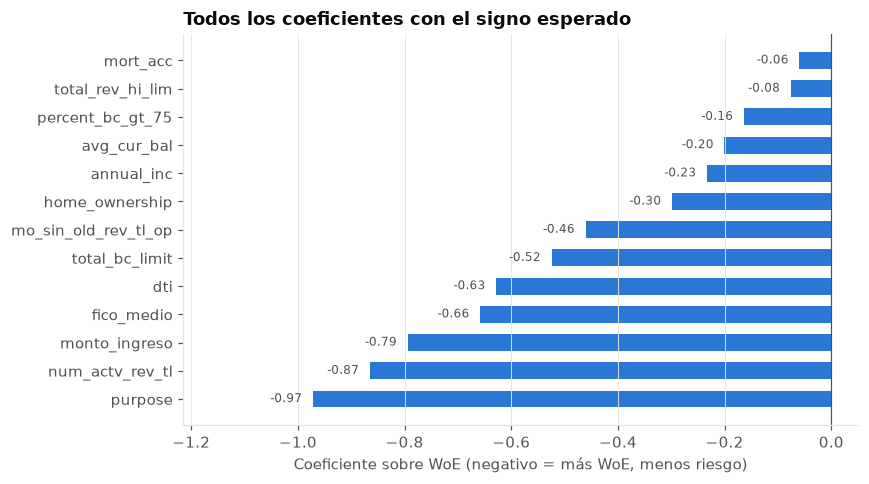

In [4]:
modelo = modelo_logistica().fit(tr[LOGISTICA], tr["malo"])
coef = pd.Series(modelo.named_steps["logistica"].coef_[0], index=LOGISTICA).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(coef.index, coef.values, color=AZUL, height=0.6)
for y, v in enumerate(coef.values):
    ax.text(v - 0.02, y, f"{v:.2f}", va="center", ha="right", fontsize=8, color=TINTA_2)
ax.axvline(0, color=TINTA_2, linewidth=0.8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Coeficiente sobre WoE (negativo = más WoE, menos riesgo)")
ax.set_title("Todos los coeficientes con el signo esperado")
ax.set_xlim(coef.min() * 1.25, 0.05)
fig.tight_layout()

## 3. El duelo: logística vs. Lending Club en 2015

In [5]:
pd_tr = modelo.predict_proba(tr[LOGISTICA])[:, 1]
pd_oot = modelo.predict_proba(oot[LOGISTICA])[:, 1]
orden_grado = oot["sub_grade"].str[0].map(dict(zip("ABCDEFG", range(7)))) * 5 + oot["sub_grade"].str[1].astype(int)

duelo = pd.DataFrame({
    "Logística · entrenamiento": resumen(tr["malo"], pd_tr),
    "Logística · OOT 2015": resumen(oot["malo"], pd_oot),
    "Benchmark int_rate · OOT 2015": discriminacion(oot["malo"], oot["int_rate"]),
    "Benchmark sub_grade · OOT 2015": discriminacion(oot["malo"], orden_grado),
}).T
duelo

,auc,gini,ks,brier,pd_media,tasa_real
Logística · entrenamiento,0.6506,0.3012,0.2176,0.1107,0.1318,0.1318
Logística · OOT 2015,0.6526,0.3052,0.2208,0.1224,0.1314,0.1489
Benchmark int_rate · OOT 2015,0.6784,0.3569,0.2621,NaN,NaN,NaN
Benchmark sub_grade · OOT 2015,0.6787,0.3573,0.2619,NaN,NaN,NaN


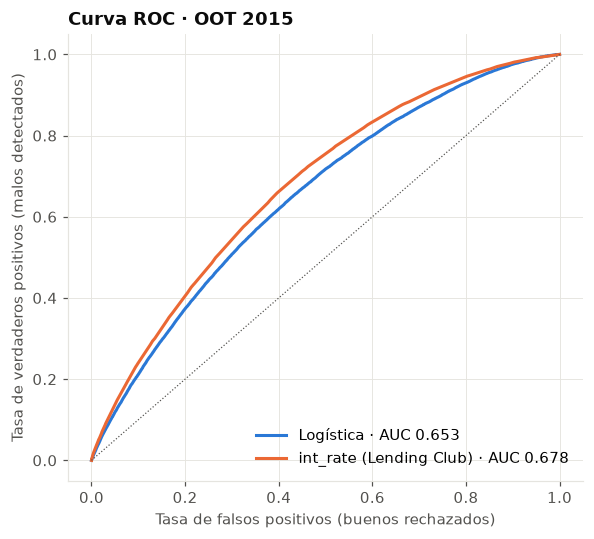

In [6]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for nombre, score, color in [("Logística", pd_oot, AZUL), ("int_rate (Lending Club)", oot["int_rate"], NARANJA)]:
    fpr, tpr, _ = roc_curve(oot["malo"], score)
    auc = discriminacion(oot["malo"], score)["auc"]
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{nombre} · AUC {auc:.3f}")
ax.plot([0, 1], [0, 1], color=TINTA_2, linewidth=0.8, linestyle=":")
ax.set_xlabel("Tasa de falsos positivos (buenos rechazados)")
ax.set_ylabel("Tasa de verdaderos positivos (malos detectados)")
ax.set_title("Curva ROC · OOT 2015")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()

## 4. Vista de negocio: tasa de malos por decil de riesgo

Si el modelo ordena bien, los deciles más riesgosos concentran muchos más malos.

,1,2,3,4,5,6,7,8,9,10
Logística,0.0437,0.0771,0.0989,0.1140,0.1342,0.1495,0.1723,0.1981,0.2236,0.2772
int_rate (Lending Club),0.0358,0.0611,0.0838,0.1090,0.1233,0.1579,0.1743,0.2059,0.2333,0.3042


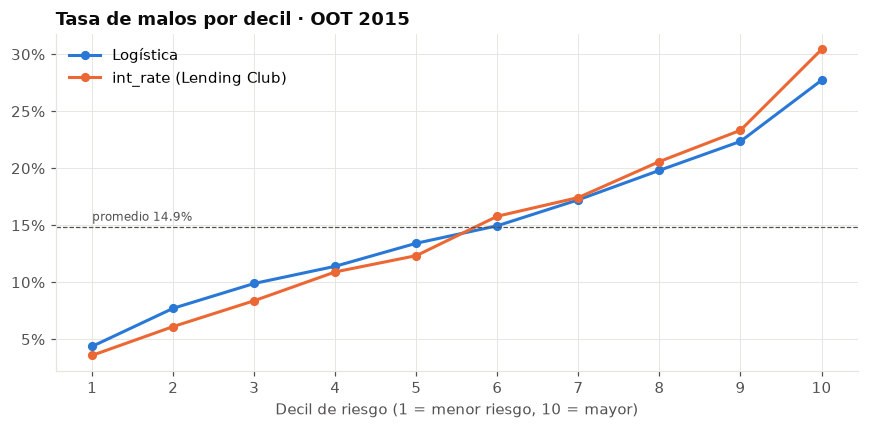

In [7]:
def por_decil(score):
    d = pd.qcut(pd.Series(score, index=oot.index).rank(method="first"), 10, labels=range(1, 11))
    return oot["malo"].groupby(d).mean()

deciles = pd.DataFrame({"Logística": por_decil(pd_oot), "int_rate (Lending Club)": por_decil(oot["int_rate"])})

fig, ax = plt.subplots(figsize=(8, 4))
for col, color in [("Logística", AZUL), ("int_rate (Lending Club)", NARANJA)]:
    ax.plot(deciles.index.astype(int), deciles[col], color=color, linewidth=2, marker="o", markersize=5, label=col)
ax.axhline(oot["malo"].mean(), color=TINTA_2, linewidth=0.8, linestyle="--")
ax.text(1, oot["malo"].mean() + 0.005, f"promedio {oot['malo'].mean():.1%}", fontsize=8, color=TINTA_2)
ax.set_xticks(range(1, 11))
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Decil de riesgo (1 = menor riesgo, 10 = mayor)")
ax.set_title("Tasa de malos por decil · OOT 2015")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
deciles.T

## 5. El scorecard en puntos

Escala: **600 puntos = odds 50:1** y **cada 20 puntos las odds se duplican**. Más puntos = menos riesgo.

Con una tasa de malos de ~13%, las odds promedio son ~6,6:1, así que el puntaje típico de esta población ronda los **540 puntos**.

In [8]:
puntos = tabla_puntos(modelo)
puntos[puntos["variable"].isin(["fico_medio", "dti", "annual_inc"])]

,variable,tramo,woe,puntos
0,fico_medio,"(-inf, 667.0]",-0.3536,35
1,fico_medio,"(667.0, 672.0]",-0.2815,36
2,fico_medio,"(672.0, 677.0]",-0.2036,38
3,fico_medio,"(677.0, 682.0]",-0.1787,38
4,fico_medio,"(682.0, 687.0]",-0.0996,40
5,fico_medio,"(687.0, 697.0]",0.0224,42
6,fico_medio,"(697.0, 707.0]",0.1863,45
7,fico_medio,"(707.0, 717.0]",0.3341,48
8,fico_medio,"(717.0, 737.0]",0.5547,52
9,fico_medio,"(737.0, inf]",0.9878,60


In [9]:
score_oot = pd_a_puntos(pd_oot)
bandas = pd.cut(score_oot, [0, 500, 520, 540, 560, 580, 1000])
pd.DataFrame({"prestamos": oot["malo"].groupby(bandas).size(),
              "tasa_malo": oot["malo"].groupby(bandas).mean()})

,prestamos,tasa_malo
"(0, 500]",96,0.3021
"(500, 520]",15482,0.2943
"(520, 540]",101071,0.2040
"(540, 560]",113227,0.1220
"(560, 580]",43333,0.0655
"(580, 1000]",9817,0.0276


## 6. Guardar el modelo y las predicciones (para la comparación de la sesión 6)

In [10]:
salida = Path("../modelos")
salida.mkdir(exist_ok=True)
joblib.dump(modelo, salida / "logistica.joblib")
pred = pd.DataFrame({"anio": oot["anio"], "malo": oot["malo"], "int_rate": oot["int_rate"],
                     "pd_logistica": pd_oot})
pred.to_parquet(salida / "predicciones_oot.parquet")
pred.shape

(283026, 4)

---
## ✍️ Conclusiones de Neider

1. La logística no tiene sobreajuste (AUC 0,651 en entrenamiento vs 0,653 en 2015), pero pierde contra Lending Club por 2,5 puntos de AUC. La diferencia está en los extremos: ellos separan mejor a los muy buenos y a los muy malos.
2. Prefiero perder una milésima de AUC y tener todos los signos lógicos. Un modelo que no se puede explicar no pasa un comité de crédito.
3. El modelo subestima el riesgo en 2015 (PD de 13,1% vs 14,9% real). Antes de usarlo para decidir hay que recalibrarlo.